<div style="background-color:#fff3cd; color:#000; border-left:6px solid #ffc107; padding:12px 16px; border-radius:4px;">
<b>This notebook is read-only. To edit it, copy it to the <code>my_workspace</code> folder by right-clicking the notebook name in the left navigation pane or choosing <i>Save Notebook As</i> from the File menu.</b>
</div>

# Qubit Bloch Sphere and SU(2) Rotations

## 1. State of a Qubit in Hilbert Space

A qubit can be expressed as a linear combination of the computational basis states in Hilbert space:

$|\psi\rangle = \alpha |0\rangle + \beta |1\rangle, \quad \text{with } \alpha, \beta \in \mathbb{C} \text{ and } |\alpha|^2 + |\beta|^2 = 1$

In code, the initial equatorial state is defined as:

$|\psi\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}$

---

## 2. Parametrization on the Bloch Sphere

Any pure qubit state can be parametrized using two angles $((\theta))$ and $((\phi))$ on the **Bloch sphere**:

$|\psi\rangle = \cos\frac{\theta}{2}|0\rangle + e^{i\phi}\sin\frac{\theta}{2}|1\rangle$

- $((\theta))$ is the polar angle (0 at the z-axis, $(\pi)$ at the opposite)  
- $((\phi))$ is the azimuthal angle (rotation in the xy-plane)

This parametrization allows us to represent the state as a point on the surface of the sphere.

---

## 3. Coordinates on the Bloch Sphere

From the state $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$, the Cartesian coordinates \((x, y, z)\) on the Bloch sphere are obtained as:

$$
\begin{aligned}
x &= 2 \, \text{Re}(\alpha^* \beta) \\
y &= 2 \, \text{Im}(\alpha^* \beta) \\
z &= |\alpha|^2 - |\beta|^2
\end{aligned}$$

In code, the function `state_to_bloch_coords` calculates exactly these coordinates, allowing us to visualize the initial and final states on the Bloch sphere.

---

## 4. Unitary Transformations: the SU(2) Group

To manipulate the state of a qubit without losing normalization, we use **unitary matrices** \(U in SU(2)\). An Rz gate, for example, corresponds to the matrix:

$[
R_z(\theta) = 
\begin{bmatrix}
e^{-i\theta/2} & 0 \\
0 & e^{i\theta/2}
\end{bmatrix}
]$

This gate rotates the qubit state around the z-axis of the Bloch sphere. In general, all information of a qubit can be encoded and manipulated through SU(2) unitary transformations, which correspond to rotations on the Bloch sphere (SO(3)).

---

## Application of the RZ Gate

Now we apply a **rotation around the z-axis** using the gate $R_z(\theta)$ with

$$
\theta = \frac{\pi}{3}.
$$

In code, this is executed as:

```python
psi_finale = Statevector(Rz @ psi.data)


=== Initial state of the QUBIT ===

[0.70710678+0.j 0.70710678+0.j]


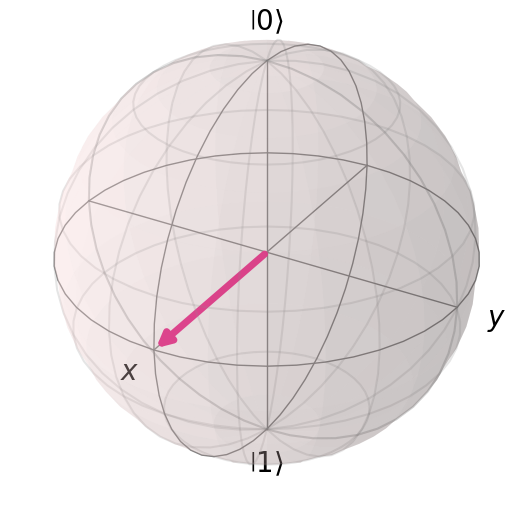


=== Gate RZ ===

Representation SU(2):
[[0.8660254-0.5j 0.       +0.j ]
 [0.       +0.j  0.8660254+0.5j]]
Representation SO(3) (rotation on Bloch sphere):
[[ 0.5       -0.8660254  0.       ]
 [ 0.8660254  0.5        0.       ]
 [ 0.         0.         1.       ]]

=== Final state of the QUBIT ===

[0.61237244-0.35355339j 0.61237244+0.35355339j]


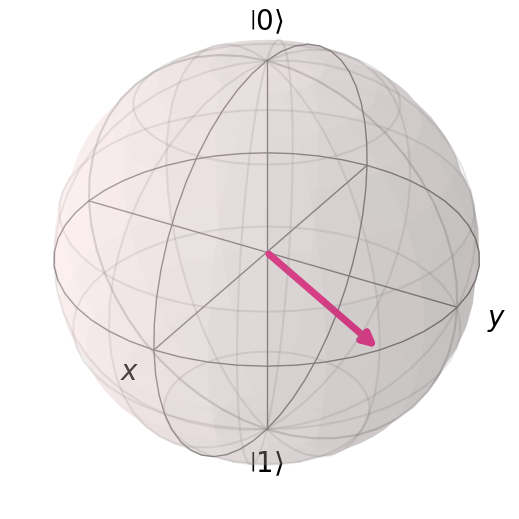

In [1]:
import numpy as np
from qiskit.quantum_info import Statevector
from qiskit.visualization.bloch import Bloch
import matplotlib.pyplot as plt

# ----------------------------
# Parameters
# ----------------------------
theta = np.pi/3  # rotation angle

# ----------------------------
# Initial state
# ----------------------------
psi = Statevector([1, 1])/np.sqrt(2)  # equatorial state

print("\n=== Initial state of the QUBIT ===\n")
print(psi.data)

# ----------------------------
# Function to convert Statevector in Bloch coordinate (x,y,z)
# ----------------------------
def state_to_bloch_coords(state):
    a = state.data[0]
    b = state.data[1]
    x = 2 * np.real(np.conj(a) * b)
    y = 2 * np.imag(np.conj(a) * b)
    z = np.abs(a)**2 - np.abs(b)**2
    return [x, y, z]

# ----------------------------
# Initial Bloch sphere 
# ----------------------------
coords_init = state_to_bloch_coords(psi)
b = Bloch()
b.add_vectors(coords_init)      
b.title = "Bloch sphere - Initial state"
b.show()

# ----------------------------
# Matrix RZ (SU(2))
# ----------------------------
Rz = np.array([
    [np.exp(-1j*theta/2), 0],
    [0, np.exp(1j*theta/2)]
])

print("\n=== Gate RZ ===\n")
print("Representation SU(2):")
print(Rz)

# ----------------------------
# Rotation SO(3)
# ----------------------------
Rz_SO3 = np.array([
    [np.cos(theta), -np.sin(theta), 0],
    [np.sin(theta),  np.cos(theta), 0],
    [0, 0, 1]
])

print("Representation SO(3) (rotation on Bloch sphere):")
print(Rz_SO3)

# ----------------------------
# Application of the Gate
# ----------------------------
psi_finale = Statevector(Rz @ psi.data)

print("\n=== Final state of the QUBIT ===\n")
print(psi_finale.data)

# ----------------------------
# Final Bloch sphere
# ----------------------------
coords_final = state_to_bloch_coords(psi_finale)
b2 = Bloch()
b2.add_vectors(coords_final)
b2.title = "Bloch sphere - final state"
b2.show()

## Quantum Circuits and Standard Gates

In addition to manually constructing matrices to rotate the qubit state, as we did with $R_z(\theta)$, we can achieve the same effect using **quantum gates** already implemented in libraries like **Qiskit**.  

This way, we can create a **quantum circuit** where each gate represents a unitary transformation of the qubit.

---

### 1. Example: Hadamard Gate H

The Hadamard gate is a very important unitary transformation, which maps the basis states $|0\rangle$ and $|1\rangle$ into **equatorial states**:

$$
H |0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}, \quad 
H |1\rangle = \frac{|0\rangle - |1\rangle}{\sqrt{2}}
$$

The **matrix representation** of the Hadamard gate is:

$$
H = \frac{1}{\sqrt{2}}
\begin{bmatrix}
1 & 1 \\
1 & -1
\end{bmatrix}
$$

This matrix is **unitary** ($H^\dagger H = I$) and can therefore be used to **modify the qubit state** without altering its normalization.

---

### 2. Building a Quantum Circuit

In Qiskit, we can define a simple circuit and apply the Hadamard gate as follows:

```python
from qiskit import QuantumCircuit

qc = QuantumCircuit(1)
qc.h(0)  # applies the Hadamard gate to qubit 0
qc.draw('mpl')

In [8]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator

theta = np.pi/3  # rotation angle

# ----------------------------
# Initial state |0>
# ----------------------------
qc = QuantumCircuit(1)
state = Statevector.from_instruction(qc)
print("=== Initial state of the QUBIT ===")
print(state.data)

# ----------------------------
# Gate Hadamard
# ----------------------------
qc_h = QuantumCircuit(1)
qc_h.h(0)
H_matrix = Operator(qc_h).data 

qc.h(0)
state = Statevector.from_instruction(qc)

print("\n=== Gate H ===")
print(H_matrix)
print("State after gate H:")
print(state.data)

# ----------------------------
# Gate RZ
# ----------------------------
qc_rz = QuantumCircuit(1)
qc_rz.rz(theta, 0)
Rz_matrix = Operator(qc_rz).data  # SU(2) di RZ

qc.rz(theta, 0)
state = Statevector.from_instruction(qc)

print("\n=== Application of the gate RZ ===")
print(Rz_matrix)
print("Final state")
print(state.data)

# ----------------------------
# Diagram of the circuit
# ----------------------------
print("\n=== Quantistic circuit ===")
print(qc.draw())

=== Initial state of the QUBIT ===
[1.+0.j 0.+0.j]

=== Gate H ===
[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]
State after gate H:
[0.70710678+0.j 0.70710678+0.j]

=== Application of the gate RZ ===
[[0.8660254-0.5j 0.       +0.j ]
 [0.       +0.j  0.8660254+0.5j]]
Final state
[0.61237244-0.35355339j 0.61237244+0.35355339j]

=== Quantistic circuit ===
   ┌───┐┌─────────┐
q: ┤ H ├┤ Rz(π/3) ├
   └───┘└─────────┘


## Quantum Measurement and Superposition

A qubit, unlike a classical bit, can exist in a **quantum superposition** of the basis states $|0\rangle$ and $|1\rangle$. This means its state can be written as $|\psi\rangle = \alpha |0\rangle + \beta |1\rangle$ where $\alpha$ and $\beta$ are complex probability amplitudes, $|\alpha|^2$ is the probability of measuring $|0\rangle$, $|\beta|^2$ is the probability of measuring $|1\rangle$, and $|\alpha|^2 + |\beta|^2 = 1$.

When a measurement is performed, the qubit **collapses** to one of the basis states: it collapses to $|0\rangle$ with probability $|\alpha|^2$ and to $|1\rangle$ with probability $|\beta|^2$. Therefore, even though the qubit exists in a superposition before measurement, the outcome of a single measurement is always **either 0 or 1**, with probabilities determined by its quantum state.


In [9]:
# Probability of measuring 0 and 1 in the final state:

probs = state.probabilities()

print("Probability of measuring 0: P(0) =", probs[0])
print("Probability of measuring 1: P(1) =", probs[1])

Probability of measuring 0: P(0) = 0.4999999999999999
Probability of measuring 1: P(1) = 0.4999999999999999
